**Building ensemble classifiers models from MotherCV**
---------------------------------------------
This notebook shows how to
1. Build a Mother pipeline and collect its fitted fold estimators using `mother_cv`.
2. Use a CV-derived ensemble as the final model in a Mother pipeline.
3. Predict labels and uncertainty through the pipeline's `predict_uncertainty()` interface.

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import FunctionTransformer
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mother import ml
from mother.ml.ensembles.cvEnsemble import EnsembleAverageUncertaintyClassifier, EnsembleDerivedUncertaintyClassifier
import mother.pipeline_utils as mother_takes_care

# Prepare data

In [2]:
df_data, df_targets = load_breast_cancer(return_X_y=True, as_frame=True)
print(f"Downloaded dataset with {df_data.shape[0]} samples and {df_data.shape[1]} features")
print(f"The target we want to predict has {len(np.unique(df_targets))} unique classes: {np.unique(df_targets)}")

Downloaded dataset with 569 samples and 30 features
The target we want to predict has 2 unique classes: [0 1]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(df_data, df_targets, test_size=0.2, random_state=42)

print(f"Training set has {X_train.shape[0]} samples and {X_train.shape[1]} features")
print(f"Test set has {X_test.shape[0]} samples and {X_test.shape[1]} features")

Training set has 455 samples and 30 features
Test set has 114 samples and 30 features


# Cross-Validation

In [4]:
model = ml.PipelineWithHyperparameterRooting(
    steps=[
        ("identity", FunctionTransformer(feature_names_out="one-to-one")),
        ("classifier", ml.CatboostClassifierMother(random_seed=42)),
    ]
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

df_cv, estimators_dict = mother_takes_care.mother_cv(
    estimator=model, X=X_train, y=y_train, cv=cv, return_estimators=True
)

0:	learn: 0.6542782	total: 53.2ms	remaining: 53.2s
1:	learn: 0.6199305	total: 56.5ms	remaining: 28.2s
2:	learn: 0.5779254	total: 57.8ms	remaining: 19.2s
3:	learn: 0.5438688	total: 59.2ms	remaining: 14.7s
4:	learn: 0.5138768	total: 60.5ms	remaining: 12s
5:	learn: 0.4770701	total: 61.9ms	remaining: 10.3s
6:	learn: 0.4504077	total: 63.3ms	remaining: 8.97s
7:	learn: 0.4239091	total: 64.7ms	remaining: 8.03s
8:	learn: 0.4009386	total: 66.2ms	remaining: 7.29s
9:	learn: 0.3775747	total: 67.7ms	remaining: 6.7s
10:	learn: 0.3556669	total: 71.6ms	remaining: 6.44s
11:	learn: 0.3378300	total: 73.4ms	remaining: 6.05s
12:	learn: 0.3202937	total: 75.9ms	remaining: 5.76s
13:	learn: 0.3049027	total: 77.2ms	remaining: 5.44s
14:	learn: 0.2935436	total: 78.5ms	remaining: 5.16s
15:	learn: 0.2793748	total: 79.9ms	remaining: 4.91s
16:	learn: 0.2644487	total: 81.2ms	remaining: 4.7s
17:	learn: 0.2521326	total: 82.5ms	remaining: 4.5s
18:	learn: 0.2430144	total: 83.9ms	remaining: 4.33s
19:	learn: 0.2314076	total:

In [5]:
df_cv.head()

,pred_target,pred_proba_0,pred_proba_1,pred_knowledge_uncertainty,pred_data_uncertainty,pred_total_uncertainty,target,iteration,test_index
68,1,0.396323,0.603677,0.010003,0.607297,0.6173,1,0,0
181,0,0.999922,0.000078,0.000006,0.001224,0.001229,0,4,1
63,1,0.000302,0.999698,0.000019,0.003931,0.00395,1,2,2
248,1,0.002761,0.997239,0.000046,0.023393,0.023439,1,1,3
60,1,0.000916,0.999084,0.000081,0.011182,0.011263,1,3,4


In [6]:
estimators_dict

{'estimators': [PipelineWithHyperparameterRooting(steps=[('identity',
                                            FunctionTransformer(feature_names_out='one-to-one')),
                                           ('classifier',
                                            CatboostClassifierMother(auto_class_weights='Balanced', boosting_type='Plain', bootstrap_type='MVS', grow_policy='SymmetricTree', learning_rate=0.03, loss_function='Logloss', max_depth=6, posterior_sampling=True, random_seed=42, random_strength=1))]),
  PipelineWithHyperparameterRooting(steps=[('identity',
                                            FunctionTransformer(feature_names_out='one-to-one')),
                                           ('classifier',
                                            CatboostClassifierMother(auto_class_weights='Balanced', boosting_type='Plain', bootstrap_type='MVS', grow_policy='SymmetricTree', learning_rate=0.03, loss_function='Logloss', max_depth=6, posterior_sampling=True, random_se

# Predict with ensemble model

To predict with an ensemble based on fitted estimators from CV, there are currently two options available:
- `EnsembleDerivedUncertaintyClassifier`: derives uncertainty from ensemble-level probabilities. The uncertainty method can be set explicitly. The default option "entropy" calculates decomposed uncertainty by mutual information between the distributions of average member vs. ensemble probability predictions.
- `EnsembleAverageUncertaintyClassifier`: averages uncertainty outputs from individual ensemble estimators.

Probabilities are predicted on ensemble-level by averaging member probabilities per sample in each case. Each ensemble is the final estimator in a `PipelineWithHyperparameterRooting`, so pipeline prediction methods delegate to the ensemble.

### EnsembleDerivedUncertaintyClassifier

In [7]:
ensemble_derived = ml.PipelineWithHyperparameterRooting(
    steps=[("ensemble", EnsembleDerivedUncertaintyClassifier(estimators=estimators_dict["estimators"]))]
)
ensemble_derived.fit(X_train, y_train)

ensemble_prediction_derived = ensemble_derived.predict_uncertainty(X=X_test, ensemble__uncertainty_method="entropy")

Ensemble members of EnsembleDerivedUncertaintyClassifier are already fitted. No refit will be performed.


In [8]:
ensemble_averaging = ml.PipelineWithHyperparameterRooting(
    steps=[("ensemble", EnsembleAverageUncertaintyClassifier(estimators=estimators_dict["estimators"]))]
)
ensemble_averaging.fit(X_train, y_train)

ensemble_prediction_averaging = ensemble_averaging.predict_uncertainty(X=X_test)

Ensemble members of EnsembleAverageUncertaintyClassifier are already fitted. No refit will be performed.


## Evaluation

In [9]:
y_pred_derived = ensemble_prediction_derived["pred"]
y_pred_averaging = ensemble_prediction_averaging["pred"]

# compute accuracy
acc_derived = accuracy_score(y_test, y_pred_derived)
acc_averaging = accuracy_score(y_test, y_pred_averaging)
print(f"Accuracy (derived): {acc_derived:.4f}; Accuracy (averaging): {acc_averaging:.4f}")

Accuracy (derived): 0.9737; Accuracy (averaging): 0.9737


> As probabilities and label predictions are commonly aggregated from estimators, accuracy scores are identical.

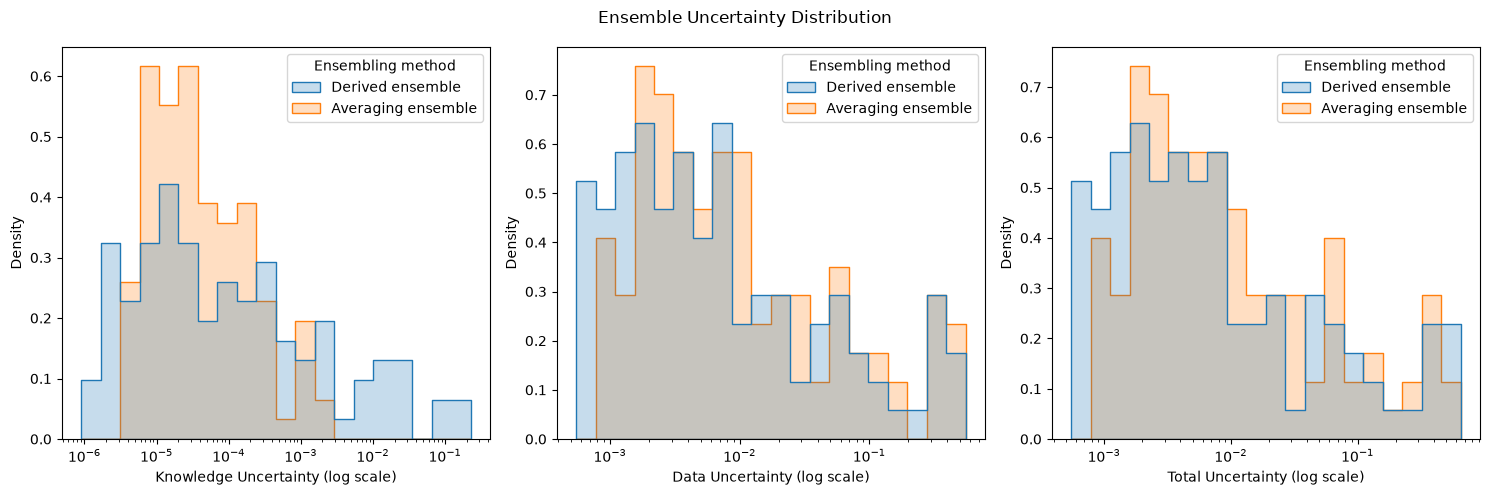

In [10]:
uncertainty_types = ["knowledge_uncertainty", "data_uncertainty", "total_uncertainty"]
ensemble_uncertainties = pd.concat(
    {
        "Derived ensemble": ensemble_prediction_derived[uncertainty_types],
        "Averaging ensemble": ensemble_prediction_averaging[uncertainty_types],
    },
    names=["Ensembling method"],
).reset_index(level="Ensembling method")

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for uncertainty_type in uncertainty_types:
    ax = axs[uncertainty_types.index(uncertainty_type)]
    sns.histplot(
        ax=ax,
        data=ensemble_uncertainties,
        x=uncertainty_type,
        hue="Ensembling method",
        bins=20,
        stat="density",
        common_norm=False,
        element="step",
        fill=True,
        log_scale=(True, False),
    )
    ax.set_xlabel(f"{uncertainty_type.replace('_', ' ').title()} (log scale)")
    ax.set_ylabel("Density")

fig.suptitle("Ensemble Uncertainty Distribution")
plt.tight_layout()
plt.show()

> As uncertainty estimation uses different strategies, distributions do not fully overlap.

The cross-validation base estimator and both ensemble variants are Mother pipelines. Each fold pipeline is fitted only on its training partition, then the fixed ensemble pipeline aggregates the fitted fold pipelines on the held-out test set. The ensemble's `fit` is a no-op because its members are already fitted; the independent test split is kept separate from cross-validation.